# Retrieval lab: how CourseMate finds the right notes

Run the cells from top to bottom with Shift+Enter.

In [1]:
# Setup: find the repo root, choose an embedder, and show which one we got.
import os
import sys
from pathlib import Path

# If Jupyter was started inside notebooks/, the repo root is the parent folder.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Make "import coursemate" work even if the package is not installed.
sys.path.insert(0, str(ROOT))

from coursemate.embeddings import FakeEmbedder, OllamaEmbedder  # noqa: E402

# Read the provider from an environment variable; default to the real local model.
PROVIDER = os.environ.get("COURSEMATE_PROVIDER", "ollama")

if PROVIDER == "fake":
    embedder = FakeEmbedder()  # hash-based vectors, no model needed
else:
    embedder = OllamaEmbedder()  # needs Ollama running with nomic-embed-text

print("Repo root:  ", ROOT)
print("Provider:   ", PROVIDER)
print("Model:      ", embedder.model)
print("Dimensions: ", embedder.dim)

Repo root:   C:\Users\rawad\Downloads\coursemate
Provider:    ollama
Model:       nomic-embed-text
Dimensions:  768


## Part A. What an embedding looks like

An embedding turns a sentence into a fixed-length list of numbers, so that sentences with similar meaning end up with similar lists.

In [2]:
# Four sentences: s0 and s1 mean almost the same thing, s2 and s3 are unrelated.
sentences = [
    "Late projects lose 10% per day.",  # s0
    "How much is the penalty for handing in work after the deadline?",  # s1
    "Merge sort runs in O(n log n) time.",  # s2
    "Office hours are on Tuesday afternoons.",  # s3
]

# Turn every sentence into a vector (a list of floats).
vectors = embedder.embed_documents(sentences)

# Every vector has the same length, and that length is the model's dimension.
print("Length of one vector:", len(vectors[0]))

# Look at just the first 5 numbers of the first vector, rounded for readability.
print("First 5 numbers:", [round(x, 3) for x in vectors[0][:5]])

Length of one vector: 768
First 5 numbers: [0.048, 0.0, -0.159, 0.004, 0.018]


In [3]:
# Cosine similarity: close to 1 means "same direction" (similar meaning), near 0 means unrelated.
from coursemate.embeddings import cosine

labels = ["s0", "s1", "s2", "s3"]

# Header row with the column labels.
print("    " + "".join(f"{label:>8}" for label in labels))

# One row per sentence: compare it with every sentence (including itself).
for i, row_label in enumerate(labels):
    row = f"{row_label:>4}"
    for j in range(len(labels)):
        row += f"{cosine(vectors[i], vectors[j]):8.3f}"
    print(row)

          s0      s1      s2      s3
  s0   1.000   0.628   0.566   0.589
  s1   0.628   1.000   0.573   0.596
  s2   0.566   0.573   1.000   0.572
  s3   0.589   0.596   0.572   1.000


## Part B. One question, three ways to search

The same question goes through vector, keyword and hybrid search. The three scores are on different scales (cosine, BM25, RRF), so compare the order of the results, not the numbers.

In [4]:
from coursemate.retrieval import MODES, retrieve
from coursemate.retrieval_eval import build_index

# Chunk and embed the sample notes into an in-memory index (no database needed).
store = build_index(ROOT / "notes" / "sample", embedder)
print("Chunks in the index:", len(store.all_chunks()))

question = "Can I get extra time on an assignment without a penalty?"
print("Question:", question)

# Search the same question in each mode and show the top 3 hits.
for mode in MODES:
    print()
    print(mode)
    hits = retrieve(question, embedder, store, k=3, mode=mode).hits
    for hit in hits:
        # hit.heading is a path like "Lecture 2 > Lab 4"; keep only the last part.
        section = hit.heading.split(" > ")[-1]
        print(f"  {hit.score:.3f}  {hit.source} > {section}")

Chunks in the index: 34
Question: Can I get extra time on an assignment without a penalty?

vector
  0.625  syllabus.md > Late work
  0.591  projects.md > Submitting work
  0.565  syllabus.md > Regrade requests

keyword
  5.756  syllabus.md > Late work
  3.035  lecture-04-sorting.md > Merge sort
  2.878  lecture-06-recursion.md > Recursion and base cases

hybrid
  0.033  syllabus.md > Late work
  0.032  projects.md > Submitting work
  0.031  lecture-06-recursion.md > Recursion and base cases


## Part C. Measure all three on the golden set

For each golden question we find the rank of the right section in each mode's results. Recall@k is the share of questions whose right section is in the top k.

In [5]:
from coursemate.retrieval_eval import evaluate, format_table, load_golden

# Load the reviewed questions, then score every mode on all of them.
golden = load_golden(ROOT / "evals" / "retrieval_golden.jsonl")
results = evaluate(golden, embedder, store)

print(format_table(results, golden))

          mode |       recall@1 |       recall@3 |       recall@5 |            MRR |    r@3 keyword | r@3 paraphrase
        vector |           0.84 |           0.96 |           1.00 |           0.90 |           1.00 |           0.92
       keyword |           0.72 |           0.76 |           0.76 |           0.73 |           1.00 |           0.50
        hybrid |           0.76 |           0.84 |           0.88 |           0.81 |           1.00 |           0.67
questions: 13 keyword, 12 paraphrase


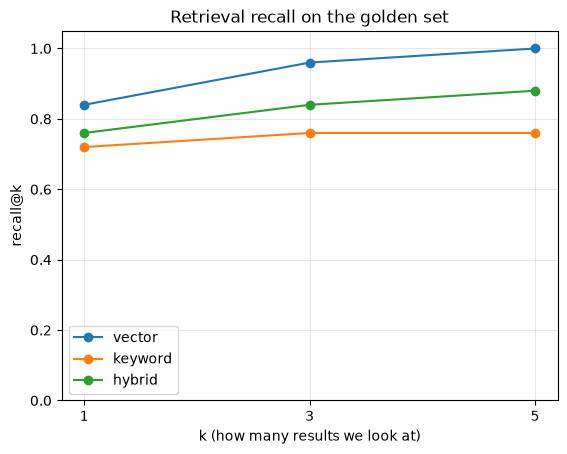

In [6]:
import matplotlib.pyplot as plt

# One line per mode: how recall grows as we look at more results.
ks = [1, 3, 5]
for result in results:
    plt.plot(ks, [result.recall(k) for k in ks], marker="o", label=result.mode)

plt.ylim(0, 1.05)  # recall is between 0 and 1; the extra 0.05 keeps the top points visible
plt.xticks(ks)
plt.xlabel("k (how many results we look at)")
plt.ylabel("recall@k")
plt.title("Retrieval recall on the golden set")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Part D. Read the misses

A miss means the right section is not in a mode's top 3. Each line shows the rank each mode gave it.

In [8]:
from coursemate.retrieval_eval import misses

missed = misses(results, golden, k=3)
if missed:
    for line in missed:
        print(line)
else:
    print("No misses: every mode found every question in its top 3.")

q02 [paraphrase] If I turn in an assignment after it was due, how much gets taken off? -> syllabus.md > Late work | vector: 1, keyword: miss, hybrid: 2
q09 [paraphrase] What happens when the buckets get too full, and why does adding stay cheap on average? -> lecture-02-hash-tables.md > Load factor and resizing | vector: 1, keyword: miss, hybrid: miss
q13 [paraphrase] Why does my tree get slow if I add values that are already in order? -> lecture-03-binary-search-trees.md > Height and running time | vector: 4, keyword: miss, hybrid: 4
q15 [paraphrase] What can make the partition-based method degrade to quadratic time? -> lecture-04-sorting.md > Quicksort | vector: 3, keyword: miss, hybrid: miss
q18 [paraphrase] Should I keep connections in a grid, or keep for each point the places it links to? -> lecture-05-graphs.md > Representing a graph | vector: 3, keyword: miss, hybrid: miss
q25 [paraphrase] The automatic checks on my repo keep failing, what should I do? -> projects.md > Submitting

## Part E. Compare saved runs

Each file in `evals/runs/` was saved with `eval-retrieval --save`, so you can compare embedding models side by side.

In [9]:
import json

print(f"{'run':<10} {'model':<18} {'mode':<8} {'r@1':>5} {'r@3':>5} {'r@5':>5} {'MRR':>5}")

# Read every saved run and print one row per run and mode.
for path in sorted((ROOT / "evals" / "runs").glob("*.json")):
    run = json.loads(path.read_text(encoding="utf-8"))
    for mode, scores in run["modes"].items():
        print(
            f"{path.stem:<10} {run['model']:<18} {mode:<8} "
            f"{scores['recall@1']:5.2f} {scores['recall@3']:5.2f} "
            f"{scores['recall@5']:5.2f} {scores['mrr']:5.2f}"
        )

run        model              mode       r@1   r@3   r@5   MRR
fake       fake               vector    0.56  0.76  0.76  0.66
fake       fake               keyword   0.72  0.76  0.76  0.73
fake       fake               hybrid    0.64  0.76  0.84  0.71
nomic      nomic-embed-text   vector    0.84  0.96  1.00  0.90
nomic      nomic-embed-text   keyword   0.72  0.76  0.76  0.73
nomic      nomic-embed-text   hybrid    0.76  0.84  0.88  0.81


## What I learned

Vector search with nomic-embed-text won: it put the right section in the top 3 for 96% of the questions (recall@3 0.96, MRR 0.90), ahead of hybrid (0.84) and keyword search (0.76). All of the gap comes from paraphrase questions, where recall@3 was 0.92 for vector, 0.67 for hybrid and 0.50 for keyword; on the questions that reuse the notes' own words, all three modes scored 1.00. Embeddings match meaning, so "the buckets get too full" finds the load factor section, while BM25 needs shared words and has no stemming, so "failing" never matches "fails". Hybrid did not help here because RRF gives the noisy keyword list the same weight as the vector list, which pushed the right section out of the top 3 for three questions and down a place for two more, though it did lift one question (q19) from rank 2 to rank 1. With only 25 questions and 34 chunks, one question moves recall by 0.04, so this is a hint to confirm on a bigger golden set, not a proof.